In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report

# 1. Charger les données
df = pd.read_csv('signal_data.csv')
X = df[['RSSI', 'SNR']].values   # les features (colonnes d'entrée)
y_true = df['is_anomaly'].values  # la vérité terrain


mean = df['RSSI'].mean()
std = df['RSSI'].std()

seuil_bas = mean - 3 * std
seuil_haut = mean + 3 * std

anomalies_3sigma = df[(df['RSSI'] < seuil_bas) | (df['RSSI'] > seuil_haut)]
contamination_estimee = len(anomalies_3sigma) / len(df)

print(f"Seuil bas : {seuil_bas:.1f} dBm")
print(f"Seuil haut : {seuil_haut:.1f} dBm")
print(f"Contamination estimée : {contamination_estimee:.3f}")



Seuil bas : -90.2 dBm
Seuil haut : -50.6 dBm
Contamination estimée : 0.035


=== Résultats Isolation Forest ===
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99       965
    Anomalie       0.76      0.74      0.75        35

    accuracy                           0.98      1000
   macro avg       0.88      0.87      0.87      1000
weighted avg       0.98      0.98      0.98      1000



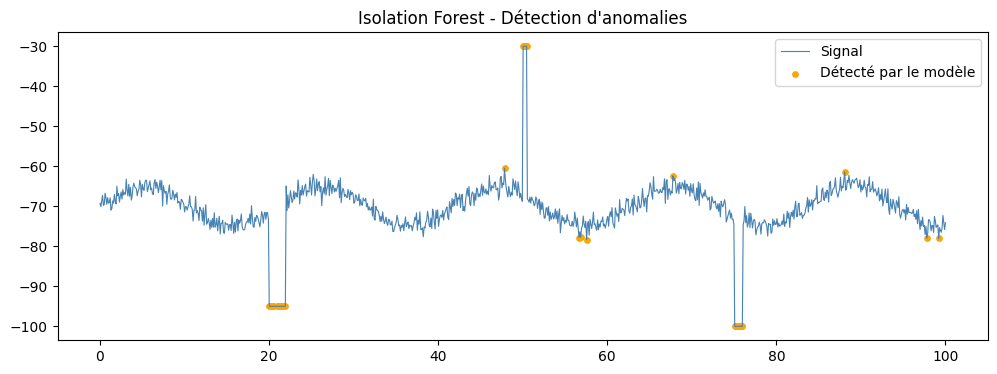

In [37]:
# 2. Créer et entraîner le modèle
model = IsolationForest(
    contamination=contamination_estimee,  # on estime 5% d'anomalies
    random_state=42
)
model.fit(X)

# 3. Prédire (-1 = anomalie, 1 = normal)
y_pred_raw = model.predict(X)
y_pred = (y_pred_raw == -1).astype(int)  # convertit en 0/1

# 4. Évaluer
print("=== Résultats Isolation Forest ===")
print(classification_report(y_true, y_pred,
      target_names=['Normal', 'Anomalie']))

# 5. Visualiser
plt.figure(figsize=(12, 4))
plt.plot(df['time'], df['RSSI'], color='steelblue',
         linewidth=0.8, label='Signal')
detected = df[y_pred == 1]
plt.scatter(detected['time'], detected['RSSI'],
            color='orange', s=15, label='Détecté par le modèle')
plt.legend()
plt.title('Isolation Forest - Détection d\'anomalies')
plt.savefig('isolation_forest_results.png', dpi=150)
plt.show()

=== Résultats Isolation Forest ===
              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99       965
    Anomalie       0.70      1.00      0.82        35

    accuracy                           0.98      1000
   macro avg       0.85      0.99      0.91      1000
weighted avg       0.99      0.98      0.99      1000



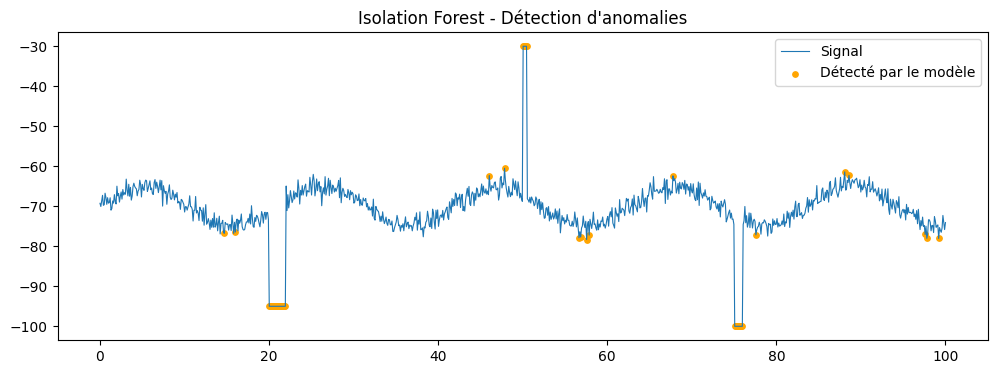

In [ ]:
# 2. Créer et entraîner le modèle
model = IsolationForest(
    contamination=0.05,  # on estime 5% d'anomalies
    random_state=42
)
model.fit(X)

# 3. Prédire (-1 = anomalie, 1 = normal)
y_pred_raw = model.predict(X)
y_pred = (y_pred_raw == -1).astype(int)  # convertit en 0/1

# 4. Évaluer
print("=== Résultats Isolation Forest ===")
print(classification_report(y_true, y_pred, target_names=['Normal', 'Anomalie']))

# 5. Visualiser
plt.figure(figsize=(12, 4))
plt.plot(df['time'], df['RSSI'], linewidth=0.8, label='Signal')
detected = df[y_pred == 1]
plt.scatter(detected['time'], detected['RSSI'], color='orange', s=15, label='Détecté par le modèle')
plt.legend()
plt.title('Isolation Forest - Détection d\'anomalies')
plt.savefig('isolation_forest_results.png', dpi=150)
plt.show()